In [1]:
%load_ext autoreload
%autoreload 2

import os
import jax
import matplotlib.pyplot as plt

import numpy as np
from flax import serialization

from c3po.analysis.analysis import C3poAnalysis
from c3po.model.model import C3PO

# analysis=C3poAnalysis(None, None, None)

# Load

## load data

In [2]:
from utils import download_ebrains_file
from pathlib import Path
local_dir = os.environ.get("C3PO_CACHE_DIR", "/stelmo/sam/tmp")  # Use environment variable if set, otherwise default
data_path = download_ebrains_file(
    remote_path="sharing_v4/navigation/of/27765_2.mat",
    local_path= Path(local_dir) / "27765_2.mat",
)

In [3]:
import numpy as np
from scipy.io import loadmat


data = loadmat(
    data_path
)


def mat_fields(s):
    """Return field names for a MATLAB struct (np.void or structured ndarray)."""
    if isinstance(s, np.ndarray) and s.dtype.names:
        return s.dtype.names
    if isinstance(s, np.void) and s.dtype.names:
        return s.dtype.names
    raise TypeError("Not a MATLAB struct (np.void/structured ndarray).")


# The 'Dsession' key gives the main struct
Dsession = data["Dsession"]

t = Dsession["t"][0, 0].flatten()  # times
x = Dsession["x"][0, 0].flatten()  # x positions
y = Dsession["y"][0, 0].flatten()  # y positions
speed = Dsession["speed"][0, 0].flatten()  #
thetaphase = Dsession["theta"][0, 0].flatten()  #
units = Dsession["units"][0, 0].flatten()  # unit data (more parsing below)
unit_cluster_id = units["mec"][0]["acorrCluId"][:]

head_dir = Dsession["hd"][0, 0].flatten()
hd_cont = np.unwrap(head_dir)
ang_vel = np.gradient(hd_cont, np.median(np.diff(t)))
ind_jump = np.where(np.diff(t) > 0.1)[0]
ang_vel[ind_jump] = 0
ang_vel[ind_jump + 1] = 0

moser_hd_decode = Dsession["lmt"][0][0][0][0][0]["id"][0][0]["XA"][0][0].flatten()
moser_hd_error = np.angle(np.exp(1j * (moser_hd_decode - head_dir)))
moser_hd_decode.shape, t.shape

((130000,), (130000,))

In [4]:
# plt.hist(np.log10(np.diff(t)))
# plt.yscale("log")
# np.median(np.diff(t))
dt = np.diff(t)

ind_valid = (dt < 0.02).astype(int)  # only use intervals with dt < 20 ms
starts = np.where(np.diff(ind_valid) == 1)[0] + 1
ends = np.where(np.diff(ind_valid) == -1)[0] + 1
if ind_valid[0]:
    starts = np.insert(starts, 0, 0)
if ind_valid[-1]:
    ends = np.append(ends, len(ind_valid))
valid_intervals = [[t[s], t[e]] for s, e in zip(starts, ends)]

# Load decoding results

In [14]:
import pandas as pd
results_dir = Path("/home/sambray/Documents/c3po_publication/decode_error_results")
all_results = {}
for results_file in results_dir.glob("*.pkl"):
    decoder_name = results_file.stem
    results = pd.read_pickle(results_file)
    print(len(results), decoder_name)
    all_results[decoder_name] = results
all_results_plus_moser = all_results.copy()
moser_results = all_results.pop("C3PO_moser")
for decoder in list(all_results.keys()):
    if "moser" in decoder:
        all_results.pop(decoder)

130000 C3PO_moser
2659022 LFADS_discretized_regression
2659022 LFADS_circular_knn
2659847 C3PO_circular_knn
2659839 CEBRA_discretized_regression
2659847 C3PO_discretized_regression
130000 LFADS_moser
2659839 CEBRA_circular_knn


# Def permutation of median errors test

In [6]:
def perm_of_medians(samples_1, samples_2, n_perms=10000):
    """Compute the permutation test of the difference of medians between two samples."""
    observed_diff = np.median(samples_1) - np.median(samples_2)
    combined_samples = np.concatenate([samples_1, samples_2])
    perm_diffs = []
    for _ in range(n_perms):
        np.random.shuffle(combined_samples)
        perm_sample_1 = combined_samples[: len(samples_1)]
        perm_sample_2 = combined_samples[len(samples_1) :]
        perm_diffs.append(np.median(perm_sample_1) - np.median(perm_sample_2))
    perm_diffs = np.array(perm_diffs)
    p_value = (np.sum(np.abs(perm_diffs) >= np.abs(observed_diff)) + 1) / (n_perms + 1)
    return observed_diff, p_value, perm_diffs

In [7]:
import numpy as np

def perm_of_means(samples_1, samples_2, n_perms=10000, seed=None):
    """Vectorized permutation test for the difference of medians."""
    rng = np.random.default_rng(seed)

    n1 = len(samples_1)
    combined = np.concatenate([samples_1, samples_2])
    n = len(combined)

    observed_diff = np.mean(samples_1) - np.mean(samples_2)

    # Generate independent random permutations
    indices = np.argsort(rng.random((n_perms, n)), axis=1)
    permuted = combined[indices]

    # Vectorized median calculation
    perm_diffs = (
        np.mean(permuted[:, :n1], axis=1)
        - np.mean(permuted[:, n1:], axis=1)
    )

    p_value = (
        np.count_nonzero(np.abs(perm_diffs) >= abs(observed_diff)) + 1
    ) / (n_perms + 1)

    return observed_diff, p_value, perm_diffs

# Compare datasets, blocked

In [ ]:
window_size = .5 #ms

# from c3po.analysis.intervals import interval_list_contains_ind
# filter_results = {}
# for decoder_name, result in all_results.items():
#     # ind = interval_list_contains_ind(valid_intervals, result.t_pred.values )
#     # errors = np.abs(result.hd_error.values[ind])
#     # filter_results[decoder_name] = errors
#     errors = []
#     for interval in tqdm(valid_intervals):
#         ind = (result.t_pred.values >= interval[0]) & (result.t_pred.values <= interval[1])
#         errors_i = np.abs(result.hd_error.values[ind])
#         dt_i = np.diff(result.t_pred.values[ind]).mean()
#         step_size = int(window_size / dt_i)
#         if step_size < 1:
#             step_size = 1
#         if ind.size<=step_size:
#             continue
#         for start in range(0, ind.size - step_size, step_size):
#             end = start + step_size
#             errors.append(errors_i[start:end].mean())

import numpy as np
from tqdm.auto import tqdm

filter_results = {}

for decoder_name, result in tqdm(all_results_plus_moser.items()):

    t = result.t_pred.to_numpy()
    err = np.abs(result.hd_error.to_numpy())

    errors = []

    for t_start, t_end in valid_intervals:

        # Fast interval lookup (requires sorted timestamps)
        i0 = np.searchsorted(t, t_start, side="left")
        i1 = np.searchsorted(t, t_end, side="right")

        n = i1 - i0

        if n < 2:
            continue

        # Extract errors within interval
        errors_i = err[i0:i1]

        # Mean sampling interval (avoids np.diff allocation)
        dt = (t[i1 - 1] - t[i0]) / (n - 1)

        if dt <= 0:
            continue

        step_size = max(1, int(window_size / dt))

        # Number of complete windows
        n_windows = n // step_size

        if n_windows == 0:
            continue

        # Truncate to complete windows and compute means
        window_means = (
            errors_i[:n_windows * step_size]
            .reshape(n_windows, step_size)
            .mean(axis=1)
        )

        errors.append(window_means)

    filter_results[decoder_name] = (
        np.concatenate(errors) if errors else np.array([])
    )



  0%|          | 0/8 [00:00<?, ?it/s]

In [17]:
filter_results.keys()
# all_results.keys()

dict_keys(['C3PO_moser', 'LFADS_discretized_regression', 'LFADS_circular_knn', 'C3PO_circular_knn', 'CEBRA_discretized_regression', 'C3PO_discretized_regression', 'LFADS_moser', 'CEBRA_circular_knn'])

In [ ]:
from tqdm import tqdm
diff_results = {}
for decoder_name, errors_1 in filter_results.items():
    # if not decoder_name=="C3PO_moser":
    #     continue
    for decoder_name_2, errors_2 in tqdm(filter_results.items()):
        if decoder_name_2 <= decoder_name:
            continue
        observed_diff, p_value, perm_diffs = perm_of_means(errors_1, errors_2, n_perms=10_000)
        print(f"{decoder_name} vs {decoder_name_2}: observed diff = {observed_diff:.4f}, p-value = {p_value:.4f}")
        diff_results[(decoder_name, decoder_name_2)] = (observed_diff, p_value, perm_diffs)

  0%|          | 0/8 [00:00<?, ?it/s]

 25%|██▌       | 2/8 [00:01<00:03,  1.53it/s]

C3PO_moser vs LFADS_discretized_regression: observed diff = 0.6966, p-value = 0.0001


 38%|███▊      | 3/8 [00:02<00:04,  1.10it/s]

C3PO_moser vs LFADS_circular_knn: observed diff = 0.6993, p-value = 0.0001


 62%|██████▎   | 5/8 [00:03<00:02,  1.38it/s]

... (47 outputs left out)

 62%|██████▎   | 5/8 [00:02<00:01,  1.77it/s]

CEBRA_circular_knn vs CEBRA_discretized_regression: observed diff = 0.0117, p-value = 0.0952


100%|██████████| 8/8 [00:03<00:00,  2.10it/s]

CEBRA_circular_knn vs LFADS_moser: observed diff = -0.2442, p-value = 0.0001


# Compare datasets

In [ ]:
from c3po.analysis.intervals import interval_list_contains_ind
filter_results = {}
for decoder_name, result in all_results.items():
    ind = interval_list_contains_ind(valid_intervals, result.t_pred.values )
    errors = np.abs(result.hd_error.values[ind])
    filter_results[decoder_name] = errors

comparisons = []
from tqdm import tqdm
for decoder_name, errors_1 in filter_results.items():
    for decoder_name_2, errors_2 in tqdm(filter_results.items()):
        if decoder_name_2 <= decoder_name:
            continue
        observed_diff, p_value, perm_diffs = perm_of_means(errors_1, errors_2, n_perms=100)
        print(f"{decoder_name} vs {decoder_name_2}: observed diff = {observed_diff:.4f}, p-value = {p_value:.4f}")

100%|██████████| 6/6 [00:10<00:00,  1.79s/it]


LFADS_circular_knn vs LFADS_discretized_regression: observed diff = 0.0004, p-value = 0.3960


 17%|█▋        | 1/6 [00:10<00:50, 10.16s/it]

C3PO_circular_knn vs LFADS_discretized_regression: observed diff = 0.0416, p-value = 0.0099


 33%|███▎      | 2/6 [00:20<00:40, 10.14s/it]

C3PO_circular_knn vs LFADS_circular_knn: observed diff = 0.0413, p-value = 0.0099


... (20 outputs left out)

 33%|███▎      | 2/6 [00:20<00:40, 10.08s/it]

CEBRA_circular_knn vs LFADS_circular_knn: observed diff = 0.4464, p-value = 0.0099


100%|██████████| 6/6 [00:30<00:00,  5.04s/it]

CEBRA_circular_knn vs CEBRA_discretized_regression: observed diff = 0.0116, p-value = 0.0099


In [6]:
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.size'] = 7
plt.rcParams.update({
    "xtick.labelsize": 6,
    "ytick.labelsize": 6
})

C3PO_discretized_regression: 0.000e+00
C3PO_circular_knn: 0.000e+00
CEBRA_discretized_regression: 0.000e+00
CEBRA_circular_knn: 0.000e+00
LFADS_discretized_regression: 0.000e+00
LFADS_circular_knn: 0.000e+00


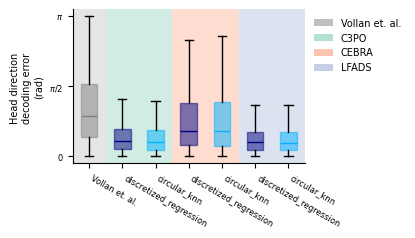

In [69]:
from c3po.analysis.intervals import interval_list_contains_ind
from scipy.stats import ttest_ind

versions = ["discretized_regression","circular_knn"]
models = ["C3PO", "CEBRA", "LFADS"]
fig, ax = plt.subplots(1, 1, figsize=(3,2))
label_list = []

i = 0
result = moser_results
ind = interval_list_contains_ind(valid_intervals, result.t_pred.values )
errors = np.abs(result.hd_error.values[ind])
ref_dist = errors
color='grey'
bp = ax.boxplot(errors, positions=[i],
    # labels=[
    #     f"Excitatory \n(n={len(corr_inhib)})",
    #     f"Inhibitory \n(n={len(corr_excit)})",
    # ],
    patch_artist=True,
    medianprops=dict(color=color, ),
    widths=0.5,
)
for box in bp["boxes"]:
    box.set_facecolor(color, )
    box.set_alpha(0.6)
for patch in bp['boxes']:
    patch.set_color(color)
    patch.set_alpha(0.5)

label_list.append(f"Vollan et. al.")

sig_locs = []
for model in models:
    for version, color in zip(versions, plt.cm.jet([0,.3])):
        decoder = f"{model}_{version}"
        # label_list.append(f"{model} ({version})")
        label_list.append(version)
        result = all_results[decoder]
        ind = interval_list_contains_ind(valid_intervals, result.t_pred.values )
        errors = np.abs(result.hd_error.values[ind])

        p_val = ttest_ind(errors, ref_dist, equal_var=False).pvalue
        print(f"{decoder}: {p_val:.3e}")
        if p_val < 0.05:
            sig_locs.append(i+1)
        # color='C0' if model=="C3PO" else 'C1' if model=="CEBRA" else 'C2'
        bp = ax.boxplot(
            errors,
            positions=[i+1],
            # labels=[
            #     f"Excitatory \n(n={len(corr_inhib)})",
            #     f"Inhibitory \n(n={len(corr_excit)})",
            # ],
            patch_artist=True,
            medianprops=dict(color=color, ),
            widths=0.5,
            showfliers=False
        )
        for box in bp["boxes"]:
            box.set_facecolor(color, )
            box.set_alpha(0.6)
        for patch in bp['boxes']:
            patch.set_color(color)
            patch.set_alpha(0.5)

        i += 1

ax.set_xticks(range(len(label_list)))
ax.set_xticklabels(label_list, rotation=-30, ha='left')

plt.ylabel("Head direction \ndecoding error \n(rad)")
ax.set_yticks([0,np.pi/2,np.pi])
ax.set_yticklabels([0, "$\pi/2$", "$\pi$"])
# plt.title("Head direction decoding error across models")
ax.spines[['top', 'right']].set_visible(False)


model_colors = {
    "C3PO": plt.cm.Set2(0),
    "CEBRA": plt.cm.Set2(1),
    "LFADS": plt.cm.Set2(2),
}


ylim = ax.get_ylim()
ax.fill_between(
    [-.5,.5],[ylim[0], ylim[0]], [ylim[1], ylim[1]], facecolor='grey', alpha=0.2,
    zorder=-1,
    label="Vollan et. al."
)

for i, model in enumerate(models):
    color = model_colors[model]
    ax.fill_between(
        [2*i+.5,2*i+2.5],[ylim[0], ylim[0]], [ylim[1], ylim[1]], facecolor=color, alpha=0.3,
        zorder=-1,
        label=model
    )
ax.set_ylim(ylim)

lg = ax.legend(loc='upper left', frameon=False, bbox_to_anchor=(1, 1),)
for handle in lg.legend_handles:
    handle.set_alpha(0.5)

fig.savefig("/home/sambray/Documents/c3po_publication/Figures/Fig3/COMPARE_head_decoding_error.svg", bbox_inches='tight', dpi=300)

In [ ]:
ref_dist = {}
model = "C3PO"
for version, color in zip(versions, plt.cm.jet([0,.3])):
    decoder = f"{model}_{version}"
    result = all_results[decoder]
    ind = interval_list_contains_ind(valid_intervals, result.t_pred.values )
    errors = np.abs(result.hd_error.values[ind])
    ref_dist[version] = errors

for model in models:
    if model == "C3PO":
        continue
    for version, color in zip(versions, plt.cm.jet([0,.3])):
        decoder = f"{model}_{version}"
        # label_list.append(f"{model} ({version})")
        label_list.append(version)
        result = all_results[decoder]
        ind = interval_list_contains_ind(valid_intervals, result.t_pred.values )
        errors = np.abs(result.hd_error.values[ind])

        p_val = ttest_ind(errors, ref_dist[version], equal_var=True).pvalue
        print(f"{decoder}: {p_val:.3e}")

CEBRA_discretized_regression: 0.000e+00
CEBRA_circular_knn: 0.000e+00
LFADS_discretized_regression: 0.000e+00
LFADS_circular_knn: 0.000e+00
